# Criação do dataset de consumo — baseline com ciclos das máquinas

**O que mudou em relação à versão anterior**

Na versão anterior, a energia das máquinas (lavar, secar, loiça) ficava dentro da *carga ativa* e era espalhada pelas horas segundo a rotina de cada perfil — deixava de existir como "evento" que o otimizador pudesse deslocar.

Agora o consumo é separado em duas partes:

| Parte | O que é | Como é gerada |
|---|---|---|
| **Carga não deslocável** | tudo o que não são as máquinas (frigorífico, luzes, forno, TV, aquecimento...) | método dos perfis **igual ao anterior**, aplicado só a esta parte |
| **Ciclos das máquinas** | máquina de lavar, de secar e da loiça, detetados nos sub-meterings do dataset UCI | ciclos reais; nos perfis sintéticos muda apenas a hora de início, segundo a rotina do perfil |

`baseline = carga não deslocável + ciclos das máquinas`

O cenário otimizado (fase seguinte) usa a mesma carga não deslocável e desloca apenas os ciclos listados em `eventos.csv`.

## 1. Importar bibliotecas e carregar os dados

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Carregar o dataset original (UCI) a partir do .txt
#    - separador ';'
#    - valores em falta marcados com '?'
colunas_num = ['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity',
               'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']
df = pd.read_csv('household_power_consumption.txt', sep=';', na_values='?',
                 dtype={c: 'float64' for c in colunas_num})

# 2. Criar a coluna Datetime (formato europeu dd/mm/aaaa) e defini-la como index
df['Datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], format='%d/%m/%Y %H:%M:%S')
df = df.drop(columns=['Date', 'Time']).set_index('Datetime')
df = df.asfreq('min')   # garante um registo por minuto (posição = minuto), minutos em falta ficam NaN
# Global_active_power: potência ativa total consumida pela casa (kW), média de cada minuto
# Sub_metering_1/2/3: energia ativa (Wh) consumida nesse minuto em cada circuito

print(f"{len(df):,} registos de {df.index.min()} a {df.index.max()}")
print(f"Minutos em falta: {df['Global_active_power'].isna().sum():,} "
      f"({df['Global_active_power'].isna().mean():.2%})")

2,075,259 registos de 2006-12-16 17:24:00 a 2010-11-26 21:02:00
Minutos em falta: 25,979 (1.25%)


In [2]:
# 3. Agregar os dados à hora (kW médio na hora = kWh consumidos nessa hora)
gap = df['Global_active_power']
df_hourly = gap.resample('h').mean()

# Horas com menos de 30 minutos válidos são consideradas em falta
minutos_validos = gap.resample('h').count()
df_hourly[minutos_validos < 30] = np.nan

# Preencher apenas falhas curtas (até 3h) por interpolação; falhas longas ficam em falta
df_hourly = df_hourly.interpolate(limit=3, limit_area='inside')


def para_matriz(serie_horaria):
    # Série horária -> matriz dias x 24 horas
    return (serie_horaria.to_frame('kW')
            .assign(dia=lambda x: x.index.normalize(), hora=lambda x: x.index.hour)
            .pivot(index='dia', columns='hora', values='kW'))


# Matriz dias x 24 horas, apenas com dias completos (os perfis são construídos dia a dia)
matriz = para_matriz(df_hourly).dropna()
print(f"Dias completos usados: {len(matriz)} de {df_hourly.index.normalize().nunique()}")

Dias completos usados: 1419 de 1442


## 2. Detetar os ciclos das máquinas (dados ao minuto)

O dataset UCI mede três circuitos separados (Wh consumidos em cada minuto; × 60/1000 → kW):

| Sub-metering | Circuito | Máquina que usamos |
|---|---|---|
| `Sub_metering_1` | cozinha: máquina da loiça, forno, micro-ondas | **máquina da loiça** |
| `Sub_metering_2` | lavandaria: máquina de lavar, máquina de secar, frigorífico, luz | **máquina de lavar** e **de secar** |
| `Sub_metering_3` | termoacumulador e ar condicionado | — (funcionam por termóstato, o utilizador não os liga) |

Só consideramos máquinas que o **utilizador liga manualmente** e pode adiar.

**Assinaturas observadas nos dados** (ver gráfico de exemplos mais abaixo):
- **Loiça:** programa de ~2 h com duas fases de aquecimento (~2,3 kW, 15–25 min) separadas por uma fase longa de circulação a baixa potência (~0,1 kW). O forno também chega a ~2,3 kW mas liga/desliga muitas vezes (termóstato) e não tem a fase longa de baixa potência; o micro-ondas tem ciclos curtos.
- **Lavar:** aquecimento da água (~2,3 kW, ~10 min) seguido de lavagem/centrifugação a baixa potência; ~0,3–0,6 kWh por ciclo.
- **Secar:** potência alta durante muito mais tempo (≥ 22 min acima de ~1,2 kW, por vezes ~4,4 kW); ~1–3 kWh por ciclo.
- **Frigorífico** (no mesmo circuito da lavandaria): ~0,06–0,12 kW de forma periódica — fica abaixo do limiar de deteção e é mantido na carga não deslocável.

In [3]:
WH_MIN_PARA_KW = 60 / 1000   # Wh consumidos num minuto -> kW médios nesse minuto
ALTO = 20                    # Wh/min (~1,2 kW): fase de aquecimento / potência alta


def detetar_blocos(serie, limiar, pausa_max):
    # Blocos contínuos com serie >= limiar, juntando pausas de até 'pausa_max' minutos.
    # Devolve uma lista de (posição_início, posição_fim), ambas inclusivas.
    ativo = serie.fillna(0).to_numpy() >= limiar
    idx = np.flatnonzero(ativo)
    if len(idx) == 0:
        return []
    quebras = np.flatnonzero(np.diff(idx) > pausa_max + 1)
    return list(zip(np.r_[idx[0], idx[quebras + 1]], np.r_[idx[quebras], idx[-1]]))


def caracterizar(serie, blocos):
    # Características de cada bloco, usadas para classificar a máquina
    v = serie.fillna(0).to_numpy()
    linhas = []
    for i, j in blocos:
        x = v[i:j + 1]
        alto = x >= ALTO
        linhas.append(dict(
            pos_ini=i, pos_fim=j, inicio=serie.index[i], duracao_min=j - i + 1,
            energia_bruta_kwh=x.sum() / 1000,                         # Wh -> kWh
            min_alto=int(alto.sum()),                                 # minutos em potência alta
            trocas=int(np.abs(np.diff(alto.astype(int))).sum()),      # nº de ligar/desligar da potência alta
            min_baixo=int(((x >= 1) & (x < ALTO)).sum()),             # minutos em potência baixa
        ))
    return pd.DataFrame(linhas)


# --- Máquina da loiça (Sub_metering_1) -------------------------------------------------
sm1 = df['Sub_metering_1']
c1 = caracterizar(sm1, detetar_blocos(sm1, limiar=1, pausa_max=10))
e_loica = c1[c1['duracao_min'].between(60, 180)        # programa completo de 1 a 3 h
             & (c1['min_baixo'] >= 30)                 # fase de circulação a baixa potência
             & (c1['trocas'] <= 8)                     # poucas fases de aquecimento (exclui o forno)
             & c1['energia_bruta_kwh'].between(0.5, 2.5)].copy()
e_loica['maquina'] = 'maq_loica'

# --- Máquinas de lavar e secar (Sub_metering_2) ----------------------------------------
sm2 = df['Sub_metering_2']
c2 = caracterizar(sm2, detetar_blocos(sm2, limiar=3, pausa_max=25))   # limiar acima do frigorífico
c2 = c2[(c2['min_alto'] >= 5) & (c2['energia_bruta_kwh'] >= 0.15)].copy()  # exclui picos curtos
e_secar = (c2['min_alto'] >= 22) & (c2['energia_bruta_kwh'] >= 0.75)
c2['maquina'] = np.where(e_secar, 'maq_secar', 'maq_lavar')

ciclos = pd.concat([e_loica, c2], ignore_index=True).sort_values('inicio', ignore_index=True)
print(ciclos['maquina'].value_counts())

maquina
maq_loica    1160
maq_secar     783
maq_lavar     633
Name: count, dtype: int64


In [4]:
# Curva de potência (kW, minuto a minuto) de cada ciclo
# Na lavandaria retira-se o nível médio do frigorífico, que continua na carga não deslocável.
em_ciclo_sm2 = np.zeros(len(df), dtype=bool)
for c in ciclos[ciclos['maquina'] != 'maq_loica'].itertuples():
    em_ciclo_sm2[c.pos_ini:c.pos_fim + 1] = True
nivel_frigorifico = sm2[~em_ciclo_sm2].mean()      # Wh/min médios fora dos ciclos
print(f"Nível médio do frigorífico (Sub_metering_2): {nivel_frigorifico * WH_MIN_PARA_KW * 1000:.0f} W")

v1, v2 = sm1.fillna(0).to_numpy(), sm2.fillna(0).to_numpy()
curvas = {}
ids = []
contador = {}
for c in ciclos.itertuples():
    contador[c.maquina] = contador.get(c.maquina, 0) + 1
    ciclo_id = f"{c.maquina}_{contador[c.maquina]:04d}"
    if c.maquina == 'maq_loica':
        kw = v1[c.pos_ini:c.pos_fim + 1] * WH_MIN_PARA_KW
    else:
        kw = np.clip(v2[c.pos_ini:c.pos_fim + 1] - nivel_frigorifico, 0, None) * WH_MIN_PARA_KW
    curvas[ciclo_id] = kw
    ids.append(ciclo_id)

ciclos['ciclo_id'] = ids
ciclos['energia_kwh'] = [curvas[i].sum() / 60 for i in ids]           # kW·min -> kWh
ciclos['potencia_media_kw'] = ciclos['energia_kwh'] / (ciclos['duracao_min'] / 60)
ciclos['potencia_max_kw'] = [curvas[i].max() for i in ids]
ciclos['dia'] = ciclos['inicio'].dt.normalize()

# Agrupar cada secagem com a lavagem que a antecede (até 4 h depois do fim da lavagem):
# nos perfis sintéticos movem-se juntas, mantendo o intervalo real entre as duas.
ciclos['grupo'] = ciclos['ciclo_id']
lavagens = ciclos[ciclos['maquina'] == 'maq_lavar']
fim_lav = lavagens['inicio'] + pd.to_timedelta(lavagens['duracao_min'], unit='min')
usadas = set()
for k, s in ciclos[ciclos['maquina'] == 'maq_secar'].iterrows():
    cand = lavagens[(fim_lav <= s['inicio']) & (fim_lav >= s['inicio'] - pd.Timedelta('4h'))
                    & ~lavagens['ciclo_id'].isin(usadas)]
    if len(cand):
        lav = cand.iloc[-1]                       # a lavagem mais recente
        usadas.add(lav['ciclo_id'])
        ciclos.loc[k, 'grupo'] = lav['ciclo_id']

resumo_ciclos = ciclos.groupby('maquina').agg(
    ciclos=('ciclo_id', 'size'),
    kwh_por_ciclo=('energia_kwh', 'median'),
    duracao_min=('duracao_min', 'median'),
    potencia_max_kw=('potencia_max_kw', 'median'),
).round(2)
resumo_ciclos['ciclos_por_semana'] = (resumo_ciclos['ciclos'] / (len(matriz) / 7)).round(1)
print(f"Secagens associadas a uma lavagem: {len(usadas)} de {(ciclos['maquina'] == 'maq_secar').sum()}")
resumo_ciclos

Nível médio do frigorífico (Sub_metering_2): 21 W


Secagens associadas a uma lavagem: 318 de 783


,ciclos,kwh_por_ciclo,duracao_min,potencia_max_kw,ciclos_por_semana
maquina,,,,,
maq_lavar,633,0.41,32.0,2.26,3.1
maq_loica,1160,1.03,114.0,2.28,5.7
maq_secar,783,1.82,68.0,2.32,3.9


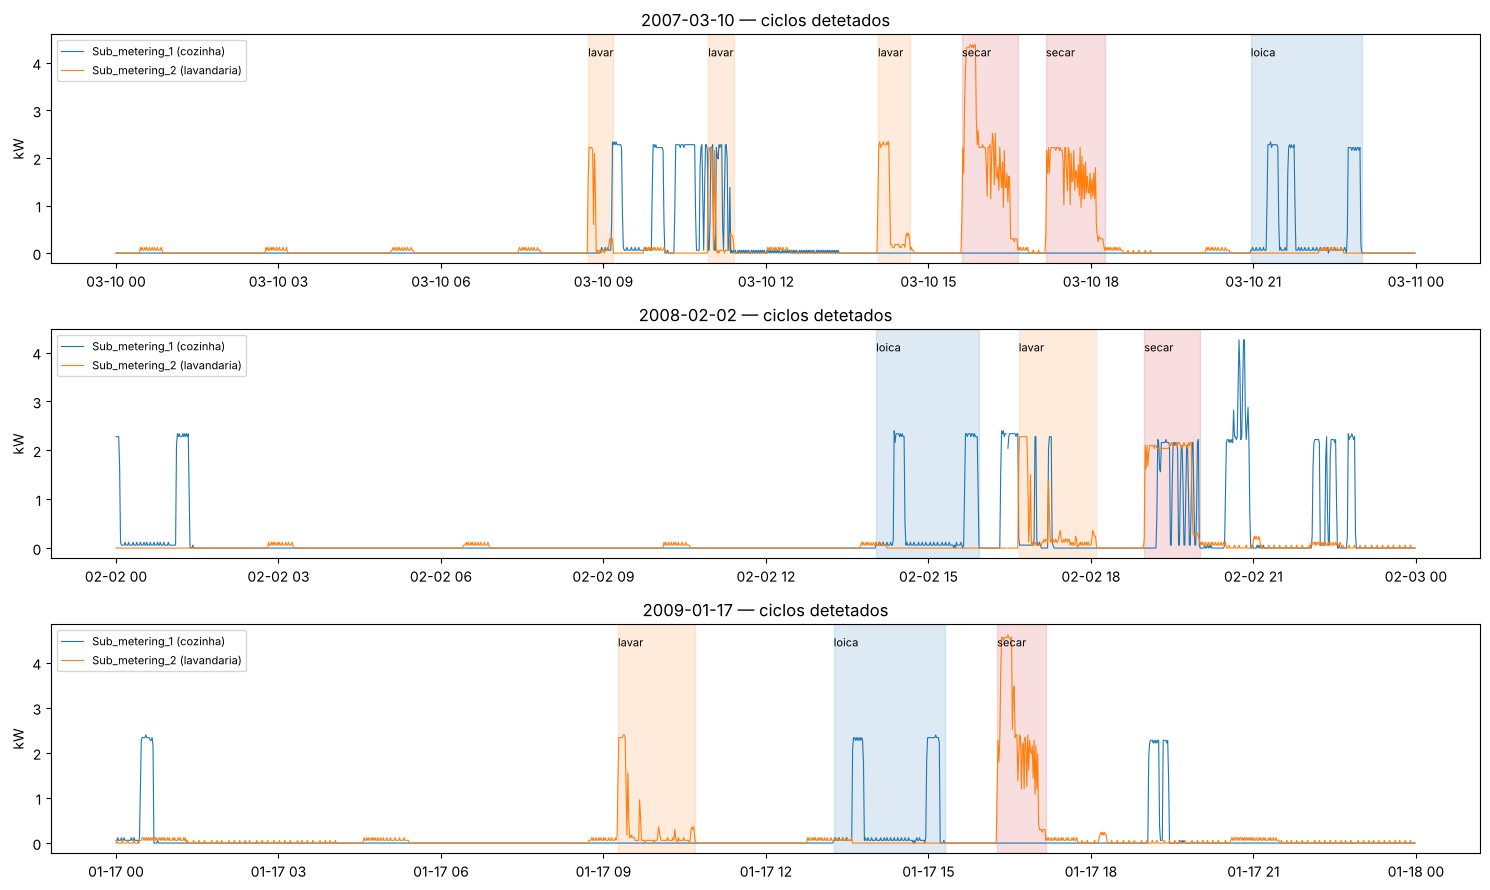

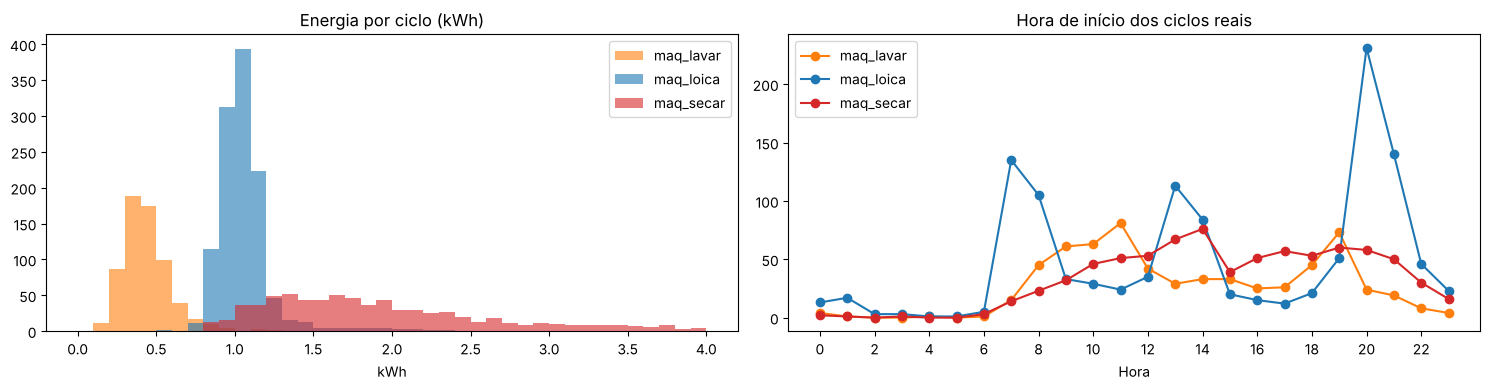

In [5]:
# Exemplos de ciclos detetados (a sombreado) sobre os sub-meterings originais
cores = {'maq_loica': 'tab:blue', 'maq_lavar': 'tab:orange', 'maq_secar': 'tab:red'}
dias_exemplo = ['2007-03-10', '2008-02-02', '2009-01-17']
fig, axes = plt.subplots(len(dias_exemplo), 1, figsize=(15, 3 * len(dias_exemplo)))
for ax, d in zip(axes, dias_exemplo):
    x = df.loc[d]
    ax.plot(x.index, x['Sub_metering_1'] * WH_MIN_PARA_KW, lw=.8, color='tab:blue', label='Sub_metering_1 (cozinha)')
    ax.plot(x.index, x['Sub_metering_2'] * WH_MIN_PARA_KW, lw=.8, color='tab:orange', label='Sub_metering_2 (lavandaria)')
    for c in ciclos[ciclos['dia'] == pd.Timestamp(d)].itertuples():
        ax.axvspan(c.inicio, c.inicio + pd.Timedelta(minutes=c.duracao_min),
                   color=cores[c.maquina], alpha=.15)
        ax.text(c.inicio, ax.get_ylim()[1] * .9, c.maquina.replace('maq_', ''), fontsize=8)
    ax.set_title(f'{d} — ciclos detetados'); ax.set_ylabel('kW'); ax.legend(loc='upper left', fontsize=8)
plt.tight_layout(); plt.show()

# Energia por ciclo e hora de início (dados reais) — comparar com os valores da API de eletrodomésticos
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for m, g in ciclos.groupby('maquina'):
    axes[0].hist(g['energia_kwh'], bins=np.arange(0, 4.01, 0.1), alpha=.6, label=m, color=cores[m])
    axes[1].plot(np.bincount(g['inicio'].dt.hour, minlength=24), marker='o', label=m, color=cores[m])
axes[0].set_title('Energia por ciclo (kWh)'); axes[0].set_xlabel('kWh'); axes[0].legend()
axes[1].set_title('Hora de início dos ciclos reais'); axes[1].set_xlabel('Hora'); axes[1].set_xticks(range(0, 24, 2))
axes[1].legend(); plt.tight_layout(); plt.show()

## 3. Carga não deslocável

Carga total **menos** a curva das máquinas, apenas nos minutos em que cada ciclo está a decorrer. Depois aplica-se exatamente a mesma limpeza horária da secção 1 e usam-se os mesmos dias completos.

In [6]:
kw_maquinas_real = np.zeros(len(df))
for c in ciclos.itertuples():
    kw_maquinas_real[c.pos_ini:c.pos_fim + 1] += curvas[c.ciclo_id]
gap_nd = (gap - kw_maquinas_real).clip(lower=0)     # NaN mantém-se onde o total está em falta
print(f"Minutos em que a subtração ficou negativa (cortados a 0): {(gap - kw_maquinas_real < 0).sum()}")

df_hourly_nd = gap_nd.resample('h').mean()
df_hourly_nd[minutos_validos < 30] = np.nan
df_hourly_nd = df_hourly_nd.interpolate(limit=3, limit_area='inside')
matriz_nd = para_matriz(df_hourly_nd).reindex(matriz.index)
assert not matriz_nd.isna().any().any()

print(f"Energia média diária: total {matriz.sum(axis=1).mean():.2f} kWh | "
      f"não deslocável {matriz_nd.sum(axis=1).mean():.2f} kWh | "
      f"máquinas {(matriz - matriz_nd).sum(axis=1).mean():.2f} kWh")

# Só ficam os ciclos que começam num dos dias completos usados nos perfis
ciclos = ciclos[ciclos['dia'].isin(matriz.index)].reset_index(drop=True)

Minutos em que a subtração ficou negativa (cortados a 0): 16
Energia média diária: total 26.19 kWh | não deslocável 23.97 kWh | máquinas 2.21 kWh


## 4. Perfis de utilizador (carga não deslocável)

Metodologia **igual à versão anterior**, agora aplicada à carga não deslocável (`M = matriz_nd`):

1. **Carga base** (frigorífico, standby, router...): mínimo horário de cada dia. Existe sempre, mesmo sem ninguém em casa.
2. **Carga ativa**: o resto do consumo, que depende do comportamento das pessoas.
3. Cada perfil define uma **rotina horária** (pesos relativos de atividade em cada hora). A energia ativa diária real é **redistribuída** pelas horas segundo essa rotina, mantendo a **variabilidade real** de cada hora (picos, dias atípicos, sazonalidade, férias).
4. Ajustes específicos por perfil: mais/menos energia (nº de pessoas, tempo em casa), equipamentos extra, ruído e limite de potência contratada.

| Perfil | Rotina (dias úteis) | Ajustes |
|---|---|---|
| 1 - Original | Agregado real (UCI) | - |
| 2 - Escritório | Fora 9h-18h, picos 6h-8h e 19h-22h | -15% energia nos dias úteis; fim de semana = original |
| 3 - Família numerosa | Pico manhã (escola), regresso 16h, jantar | +70% energia ativa, +40% base, ruído com memória, 9.2 kVA; **+40% ciclos das máquinas** |
| 4 - Trabalhador noturno | Turno 22h-7h (seg-sex), dorme 9h-15h | -5% energia, folgas com rotina deslocada para a noite |
| 5 - Home office | Em casa todo o dia, almoço em casa | +15% energia, PC/monitores 9h-18h, aquecimento/arrefecimento sazonal |

In [7]:
M = matriz_nd   # carga não deslocável (na versão anterior: matriz, com as máquinas incluídas)

# 4. Decompor o consumo em carga base + carga ativa
horas = np.arange(24)
dias = M.index
D = len(dias)
fim_de_semana = np.asarray(dias.dayofweek >= 5)

base = M.min(axis=1).to_numpy()                 # kW sempre ligados (D,)
ativa = M.to_numpy() - base[:, None]            # kW dependentes de comportamento (D, 24)
energia_ativa = ativa.sum(axis=1)               # kWh ativos por dia

# Forma média do agregado original (dias úteis vs fim de semana)
forma_orig_semana = ativa[~fim_de_semana].mean(axis=0)
forma_orig_fds = ativa[fim_de_semana].mean(axis=0)
forma_orig = np.where(fim_de_semana[:, None], forma_orig_fds, forma_orig_semana)

# Variabilidade real: quanto cada hora se afasta da média dessa hora (1 = normal)
# Limitada para evitar picos irrealistas nas horas de consumo médio muito baixo
variabilidade = np.clip(ativa / forma_orig, 0.25, 4.0)

# Dias em que a casa original esteve praticamente vazia (férias, ausências)
em_casa = energia_ativa > 0.25 * np.median(energia_ativa)

POTENCIA_CONTRATADA = 6.9  # kVA, potência típica de uma habitação


def rotina(blocos, padrao=0.1):
    # Vetor de 24 pesos. blocos = {(hora_inicio, hora_fim_exclusiva): peso}.
    w = np.full(24, padrao, dtype=float)
    for (inicio, fim), valor in blocos.items():
        w[inicio:fim] = valor
    return w


def por_dia(semana, fds):
    # Matriz (D, 24): uma rotina para dias úteis e outra para o fim de semana.
    return np.where(fim_de_semana[:, None], fds, semana)


def gerar_perfil(pesos, fator_energia=1.0, fator_base=1.0, extra=None, ruido=None,
                 limite=POTENCIA_CONTRATADA):
    '''
    pesos: matriz (D, 24) com a rotina horária do perfil (valores relativos)
    fator_energia: escalar ou (D,), multiplica a energia ativa diária
    fator_base: multiplica a carga base (ex.: arca congeladora extra)
    extra: matriz (D, 24) em kW somada no fim (ex.: computador do teletrabalho)
    ruido: matriz (D, 24) multiplicativa
    '''
    padrao = pesos * variabilidade
    padrao = padrao / padrao.sum(axis=1, keepdims=True)
    energia = energia_ativa * np.broadcast_to(fator_energia, (D,))
    consumo = base[:, None] * fator_base + padrao * energia[:, None]
    if extra is not None:
        consumo = consumo + extra
    if ruido is not None:
        consumo = consumo * ruido
    return np.clip(consumo, 0.05, limite)

In [8]:
perfis = {}
rotinas = {}           # pesos (D, 24) de cada perfil -> usados também para pôr os ciclos das máquinas
horario_real = {}      # (D,) True nos dias em que o perfil segue o comportamento original

# Perfil 1: O Consumo Base (Original)
perfis['Perfil_1_Original'] = M.to_numpy()
rotinas['Perfil_1_Original'] = forma_orig
horario_real['Perfil_1_Original'] = np.ones(D, dtype=bool)

# Perfil 2: Trabalhador de Escritório
# Dias úteis: acorda às 6h, sai às 8h-9h, regressa às 18h; só a carga base fica ligada durante o dia
# Fim de semana: rotina igual ao agregado original
escritorio_semana = rotina({(0, 6): 0.12, (6, 8): 1.3, (8, 9): 0.5, (9, 18): 0.05,
                            (18, 19): 0.9, (19, 22): 1.6, (22, 23): 1.0, (23, 24): 0.5})
rotinas['Perfil_2_Escritorio'] = por_dia(escritorio_semana, forma_orig_fds)
horario_real['Perfil_2_Escritorio'] = fim_de_semana
perfis['Perfil_2_Escritorio'] = gerar_perfil(
    rotinas['Perfil_2_Escritorio'],
    fator_energia=np.where(fim_de_semana, 1.0, 0.85),   # menos horas em casa nos dias úteis
)

# Perfil 3: Família Numerosa (2 adultos + 3 crianças)
# Mais pessoas -> mais energia ativa (cozinha, banhos, luzes) e mais carga base (arca extra)
# Ruído multiplicativo: componente diária com memória (dias seguidos parecidos) + componente horária
rng = np.random.default_rng(42)
z = np.zeros(D)
eps = rng.normal(0, 0.08, D)
for i in range(1, D):
    z[i] = 0.7 * z[i - 1] + eps[i]
ruido_familia = np.exp(z[:, None] + rng.normal(0, 0.12, (D, 24)))

familia_semana = rotina({(0, 6): 0.15, (6, 7): 1.2, (7, 8): 1.8, (8, 9): 0.8, (9, 12): 0.35,
                         (12, 14): 0.6, (14, 16): 0.35, (16, 19): 1.0, (19, 22): 1.8,
                         (22, 23): 1.0, (23, 24): 0.4})
familia_fds = rotina({(0, 7): 0.15, (7, 8): 0.6, (8, 11): 1.2, (11, 14): 1.5, (14, 19): 1.0,
                      (19, 22): 1.6, (22, 23): 1.0, (23, 24): 0.5})
rotinas['Perfil_3_Familia'] = por_dia(familia_semana, familia_fds)
horario_real['Perfil_3_Familia'] = np.zeros(D, dtype=bool)
perfis['Perfil_3_Familia'] = gerar_perfil(
    rotinas['Perfil_3_Familia'],
    fator_energia=1.7, fator_base=1.4, ruido=ruido_familia, limite=9.2,
)

# Perfil 4: Trabalhador Noturno
# Turno 22h-7h com entrada de segunda a sexta à noite (sai de terça a sábado de manhã)
# Depois do turno: refeição/banho, dorme 9h-15h, ativo à tarde/noite, sai às 21h30
# Folgas (dom/seg de dia): mantém o ritmo deslocado -> deita-se tarde e acorda tarde
dow = np.asarray(dias.dayofweek)
trabalha_hoje = dow < 5                        # entra às 22h
saiu_do_turno = (dow >= 1) & (dow <= 5)        # chegou a casa às 7h

madrugada_folga = rotina({(0, 2): 1.0, (2, 3): 0.5}, padrao=0.12)
dia_pos_turno = rotina({(7, 9): 1.2, (9, 15): 0.08, (15, 17): 0.8, (17, 21): 1.4, (21, 22): 1.0})
dia_folga = rotina({(7, 10): 0.12, (10, 11): 0.6, (11, 14): 1.2, (14, 19): 0.9, (19, 22): 1.5})
noite_em_casa = rotina({(22, 23): 1.3, (23, 24): 1.1})

noturno = np.empty((D, 24))
noturno[:, 0:7] = np.where(saiu_do_turno[:, None], 0.02, madrugada_folga[0:7])
noturno[:, 7:22] = np.where(saiu_do_turno[:, None], dia_pos_turno[7:22], dia_folga[7:22])
noturno[:, 22:24] = np.where(trabalha_hoje[:, None], 0.02, noite_em_casa[22:24])
rotinas['Perfil_4_Noturno'] = noturno
horario_real['Perfil_4_Noturno'] = np.zeros(D, dtype=bool)
perfis['Perfil_4_Noturno'] = gerar_perfil(noturno, fator_energia=0.95)

# Perfil 5: Home Office (teletrabalho nos dias úteis)
# Em casa o dia todo: consumo diurno moderado, almoço cozinhado em casa
# Extra: PC + monitores + router (~120 W) 9h-18h e climatização do escritório consoante o mês
home_semana = rotina({(0, 6): 0.12, (6, 7): 0.5, (7, 9): 1.1, (9, 12): 0.6, (12, 14): 1.3,
                      (14, 18): 0.6, (18, 19): 0.9, (19, 22): 1.4, (22, 23): 0.9, (23, 24): 0.4})
climatizacao = {1: 0.40, 2: 0.32, 3: 0.20, 4: 0.08, 5: 0.0, 6: 0.05,
                7: 0.15, 8: 0.15, 9: 0.0, 10: 0.08, 11: 0.24, 12: 0.40}   # kW médios
horario_trabalho = rotina({(9, 18): 1.0}, padrao=0.0)
dia_teletrabalho = (~fim_de_semana) & em_casa
kw_extra = 0.12 + np.asarray(dias.month.map(climatizacao), dtype=float)
extra_home = (dia_teletrabalho * kw_extra)[:, None] * horario_trabalho

rotinas['Perfil_5_HomeOffice'] = por_dia(home_semana, forma_orig_fds)
horario_real['Perfil_5_HomeOffice'] = fim_de_semana
perfis['Perfil_5_HomeOffice'] = gerar_perfil(
    rotinas['Perfil_5_HomeOffice'],
    fator_energia=np.where(fim_de_semana, 1.0, 1.15),
    extra=extra_home,
)

## 5. Ciclos das máquinas em cada perfil

**Regras**
- Cada dia mantém os **ciclos reais** desse dia (quantos, que máquina, duração, energia e curva de potência) → frequência e sazonalidade reais.
- **Perfil 1** e os **fins de semana dos perfis 2 e 5** (que seguem o comportamento original): ciclos nas **horas reais**.
- **Restantes dias**: só muda a **hora de início**, sorteada com probabilidade proporcional à rotina do perfil, **apenas nas horas em que a pessoa está em casa e acordada** (peso ≥ 50% do máximo desse dia — ver `disponibilidade.csv`).
- A carga horária (não deslocável + máquinas) não pode passar a **potência contratada** do perfil (6,9 kVA; 9,2 kVA na família).
- A mesma máquina não pode ter dois ciclos sobrepostos (incluindo ciclos que passam da meia-noite); a secagem acompanha a lavagem a que está associada, com o intervalo real entre as duas, e também tem de começar numa hora disponível.
- Se não houver nenhuma hora que cumpra as regras, o ciclo fica na hora real (o número de casos é impresso).
- **Família numerosa:** **+40% ciclos** (moderado), sorteados entre os ciclos reais do mesmo mês e colocados em dias do mesmo mês em que a casa está ocupada. O restante aumento de consumo (+70% energia ativa) já está na carga não deslocável.
- Seed fixa → resultados reprodutíveis.

In [9]:
rng_ciclos = np.random.default_rng(2026)
FRACAO_DISPONIVEL = 0.5     # hora disponível se peso >= 50% do máximo do dia
EXTRA_FAMILIA = 0.4         # +40% ciclos no perfil Família
inicio_dia = {d: i for i, d in enumerate(dias)}

ciclos['offset_min'] = ((ciclos['inicio'] - ciclos.groupby('grupo')['inicio'].transform('min'))
                        .dt.total_seconds() // 60).astype(int)
grupos = {g: t.sort_values('offset_min') for g, t in ciclos.groupby('grupo')}
grupos_por_dia = ciclos.groupby('dia')['grupo'].unique().to_dict()

# Horas disponíveis (em casa e acordado) por perfil: (D, 24) booleano
disponivel = {}
for p, w in rotinas.items():
    w = np.asarray(w, dtype=float)
    disponivel[p] = w >= FRACAO_DISPONIVEL * w.max(axis=1, keepdims=True)


# Limite de potência: a carga horária (não deslocável + máquinas) não pode passar a potência contratada
LIMITE = {p: (9.2 if p == 'Perfil_3_Familia' else POTENCIA_CONTRATADA) for p in perfis}
n_dias_cal = (dias[-1] - dias[0]).days + 2
linhas_dias = ((dias - dias[0]).days).to_numpy()


def cabe(ocupados, maquina, ini, fim):
    # True se [ini, fim) não se sobrepõe a outro ciclo da mesma máquina (no dia, no anterior e no seguinte)
    return all(fim <= a or ini >= b for oc in ocupados for a, b in oc.get(maquina, []))


def contributo_horario(grupo, ini):
    # kW médios que o grupo acrescenta a cada hora (hora contada desde o 1.º dia, 00h)
    out = {}
    for c in grupo.itertuples():
        m0 = int((ini - dias[0]).total_seconds() // 60) + c.offset_min
        curva = curvas[c.ciclo_id]
        h_abs = (m0 + np.arange(len(curva))) // 60
        soma = np.bincount(h_abs - h_abs[0], weights=curva) / 60
        for k, v in enumerate(soma):
            out[h_abs[0] + k] = out.get(h_abs[0] + k, 0.0) + v
    return out


def sortear_inicio(grupo, d, pesos, disp, ocupados, carga, limite, tentativas=30, so_primeiro=False):
    # Sorteia a hora de início do grupo no dia d (índice); devolve Timestamp ou None.
    # ocupados: ciclos já colocados no dia anterior, no próprio dia e no seguinte.
    p = np.where(disp, pesos, 0.0)
    if p.sum() <= 0:
        return None
    p = p / p.sum()
    for _ in range(tentativas):
        h = rng_ciclos.choice(24, p=p)
        ini = dias[d] + pd.Timedelta(hours=int(h), minutes=int(rng_ciclos.integers(60)))
        inicios = [ini + pd.Timedelta(minutes=c.offset_min) for c in grupo.itertuples()]
        # todas as máquinas do grupo (ex.: a secagem) também têm de começar numa hora disponível do mesmo dia
        # (so_primeiro=True: 2.ª tentativa, mais flexível, em que só a 1.ª máquina tem de estar na janela)
        na_janela = all(t.normalize() == dias[d] and disp[t.hour] for t in (inicios[:1] if so_primeiro else inicios))
        sem_sobreposicao = all(cabe(ocupados, c.maquina, t, t + pd.Timedelta(minutes=c.duracao_min))
                               for c, t in zip(grupo.itertuples(), inicios))
        dentro_limite = all(h_abs >= len(carga) or not (carga[h_abs] + v > limite)
                            for h_abs, v in contributo_horario(grupo, ini).items())
        if na_janela and sem_sobreposicao and dentro_limite:
            return ini
    return None


def registar(eventos, ocupado, carga, perfil, grupo, ini, origem):
    for h_abs, v in contributo_horario(grupo, ini).items():
        if h_abs < len(carga):
            carga[h_abs] += v
    for c in grupo.itertuples():
        i = ini + pd.Timedelta(minutes=c.offset_min)
        f = i + pd.Timedelta(minutes=c.duracao_min)
        ocupado.setdefault(c.maquina, []).append((i, f))
        eventos.append(dict(perfil=perfil, maquina=c.maquina, ciclo_id=c.ciclo_id, origem=origem,
                            inicio=i, fim=f, duracao_min=c.duracao_min,
                            energia_kwh=round(c.energia_kwh, 3),
                            potencia_media_kw=round(c.potencia_media_kw, 3)))


lista_eventos = []
sem_lugar = {}                                         # grupos que ficaram na hora real por falta de lugar
for p in perfis:
    pesos_p, disp_p, real_p = np.asarray(rotinas[p], dtype=float), disponivel[p], horario_real[p]
    # carga horária já ocupada (não deslocável + máquinas colocadas), em horas desde o 1.º dia
    carga = np.full(n_dias_cal * 24, -np.inf)          # -inf = dia fora do dataset (sem verificação)
    carga.reshape(n_dias_cal, 24)[linhas_dias] = perfis[p]
    ocupado_dia = {}                                   # dia -> {máquina: [(ini, fim), ...]}
    sem_lugar[p] = 0
    vizinhos = lambda d: [ocupado_dia.setdefault(k, {}) for k in (d - 1, d, d + 1)]
    for d, dia in enumerate(dias):
        ocupado = ocupado_dia.setdefault(d, {})
        for g in grupos_por_dia.get(dia, []):
            grupo = grupos[g]
            ini_real = grupo['inicio'].iloc[0]
            ini = None
            if not real_p[d]:
                ini = sortear_inicio(grupo, d, pesos_p[d], disp_p[d], vizinhos(d), carga, LIMITE[p])
                if ini is None:
                    ini = sortear_inicio(grupo, d, pesos_p[d], disp_p[d], vizinhos(d), carga, LIMITE[p],
                                         so_primeiro=True)
                sem_lugar[p] += ini is None
            registar(lista_eventos, ocupado, carga, p, grupo, ini if ini is not None else ini_real,
                     'real' if ini is None else 'realocado')

    # Família: ciclos extra, sorteados entre os grupos reais do mesmo mês
    if p == 'Perfil_3_Familia':
        mes = dias.to_period('M')
        for periodo in mes.unique():
            dias_mes = np.flatnonzero((mes == periodo) & em_casa)
            g_mes = [g for dia in dias[mes == periodo] for g in grupos_por_dia.get(dia, [])]
            if len(dias_mes) == 0 or len(g_mes) == 0:
                continue
            for _ in range(int(round(EXTRA_FAMILIA * len(g_mes)))):
                grupo = grupos[g_mes[rng_ciclos.integers(len(g_mes))]]
                for _ in range(10):                    # procura um dia do mês onde caiba
                    d = int(rng_ciclos.choice(dias_mes))
                    ini = sortear_inicio(grupo, d, pesos_p[d], disp_p[d], vizinhos(d), carga, LIMITE[p])
                    if ini is not None:
                        registar(lista_eventos, ocupado_dia.setdefault(d, {}), carga, p, grupo, ini, 'extra')
                        break

eventos = (pd.DataFrame(lista_eventos).sort_values(['perfil', 'inicio'], ignore_index=True))
eventos.insert(0, 'evento_id', [f"E{i:06d}" for i in range(len(eventos))])
print("Grupos sem hora disponível dentro dos limites (ficaram na hora real):", sem_lugar)
eventos.groupby(['perfil', 'origem']).size().unstack(fill_value=0)

Grupos sem hora disponível dentro dos limites (ficaram na hora real): {'Perfil_1_Original': 0, 'Perfil_2_Escritorio': 0, 'Perfil_3_Familia': 0, 'Perfil_4_Noturno': 0, 'Perfil_5_HomeOffice': 0}


origem,extra,real,realocado
perfil,,,
Perfil_1_Original,0,2563,0
Perfil_2_Escritorio,0,1015,1548
Perfil_3_Familia,1027,0,2563
Perfil_4_Noturno,0,0,2563
Perfil_5_HomeOffice,0,1015,1548


In [10]:
# Potência horária das máquinas em cada perfil (kW médio na hora), a partir das curvas minuto a minuto
# Calendário ao minuto que cobre todos os dias (+1 dia para ciclos que passam da meia-noite)
calendario = pd.date_range(dias[0], periods=n_dias_cal * 1440, freq='min')
pos_cal = pd.Series(np.arange(len(calendario)), index=calendario)


def maquinas_horario(ev):
    kw = np.zeros(len(calendario))
    for e in ev.itertuples():
        i = int(pos_cal[e.inicio])
        curva = curvas[e.ciclo_id]
        kw[i:i + len(curva)] += curva[:len(kw) - i]
    horario = kw[:(len(calendario) // 1440) * 1440].reshape(-1, 24, 60).mean(axis=2)  # (dias calendário, 24)
    return horario[linhas_dias]


maquinas = {p: maquinas_horario(eventos[eventos['perfil'] == p]) for p in perfis}
baseline = {p: perfis[p] + maquinas[p] for p in perfis}

## 6. Validação

In [11]:
# 6.1 O Perfil 1 reconstruído (carga não deslocável + ciclos nas horas reais) tem de bater com o original
erro = baseline['Perfil_1_Original'] - matriz.to_numpy()
print(f"Perfil 1 reconstruído vs original: erro médio absoluto {np.abs(erro).mean() * 1000:.1f} W, "
      f"máximo {np.abs(erro).max():.3f} kW, "
      f"{(np.abs(erro) > 0.05).mean():.2%} das horas com erro > 50 W")
print("(diferenças só em horas com minutos em falta: aí as curvas contam o ciclo inteiro e o total só os minutos válidos)")

# 6.2 Resumo por perfil
semanas = D / 7
linhas = []
for p in perfis:
    ev = eventos[eventos['perfil'] == p]
    linha = {'Perfil': p,
             'kWh/dia total': baseline[p].sum(axis=1).mean(),
             'kWh/dia não deslocável': perfis[p].sum(axis=1).mean(),
             'kWh/dia máquinas': maquinas[p].sum(axis=1).mean(),
             '% máquinas': 100 * maquinas[p].sum() / baseline[p].sum(),
             'Pico horário (kW)': baseline[p].max()}
    for m in ['maq_lavar', 'maq_secar', 'maq_loica']:
        linha[f'{m} /semana'] = (ev['maquina'] == m).sum() / semanas
    linhas.append(linha)
resumo = pd.DataFrame(linhas).set_index('Perfil').round(2)

# Comparação com a versão anterior do dataset (se o ficheiro antigo existir na pasta)
if os.path.exists('dataset_consumo_simulado.csv'):
    antigo = pd.read_csv('dataset_consumo_simulado.csv', index_col=0, parse_dates=True)
    resumo['kWh/dia versão anterior'] = antigo.resample('D').sum().replace(0, np.nan).mean().round(2)
resumo

Perfil 1 reconstruído vs original: erro médio absoluto 0.0 W, máximo 0.429 kW, 0.01% das horas com erro > 50 W
(diferenças só em horas com minutos em falta: aí as curvas contam o ciclo inteiro e o total só os minutos válidos)


,kWh/dia total,kWh/dia não deslocável,kWh/dia máquinas,% máquinas,Pico horário (kW),maq_lavar /semana,maq_secar /semana,maq_loica /semana,kWh/dia versão anterior
Perfil,,,,,,,,,
Perfil_1_Original,26.19,23.97,2.21,8.45,6.56,3.11,3.84,5.69,26.19
Perfil_2_Escritorio,24.44,22.23,2.21,9.05,6.90,3.11,3.84,5.69,24.23
Perfil_3_Familia,42.25,39.17,3.08,7.29,9.20,4.40,5.30,8.01,42.90
Perfil_4_Noturno,25.32,23.10,2.21,8.74,6.90,3.11,3.84,5.69,25.18
Perfil_5_HomeOffice,29.69,27.48,2.21,7.45,6.90,3.11,3.84,5.69,29.89


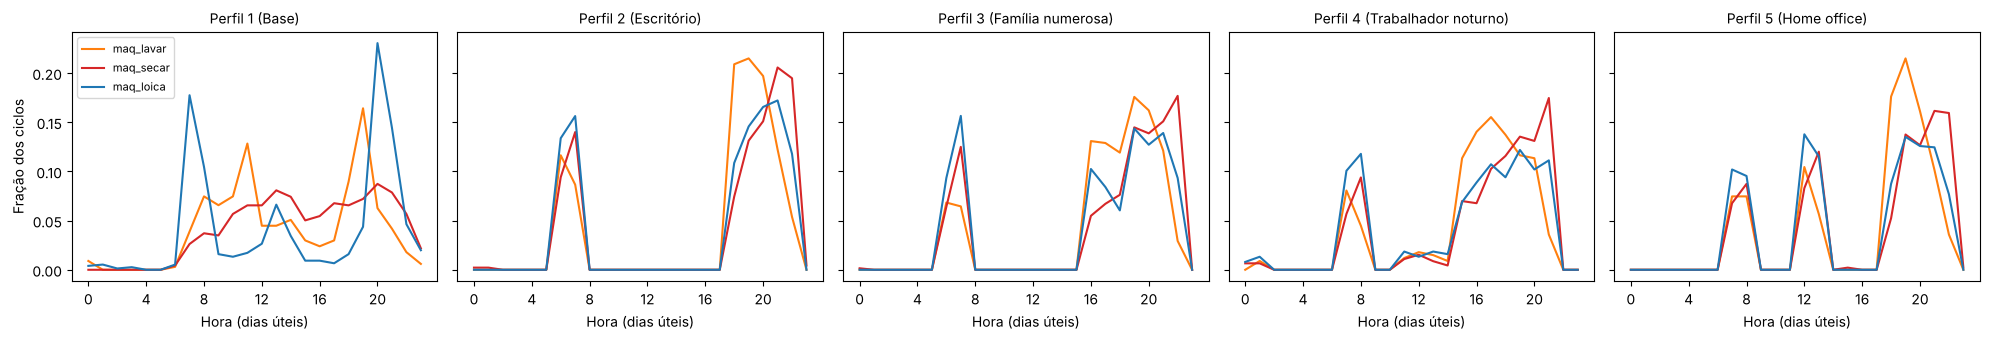

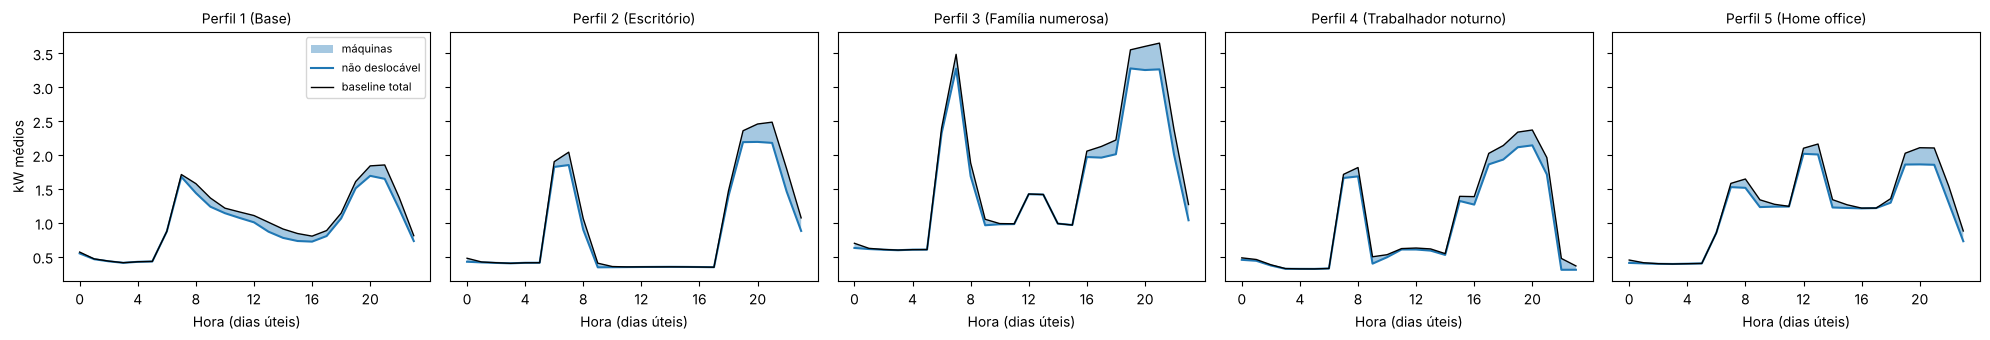

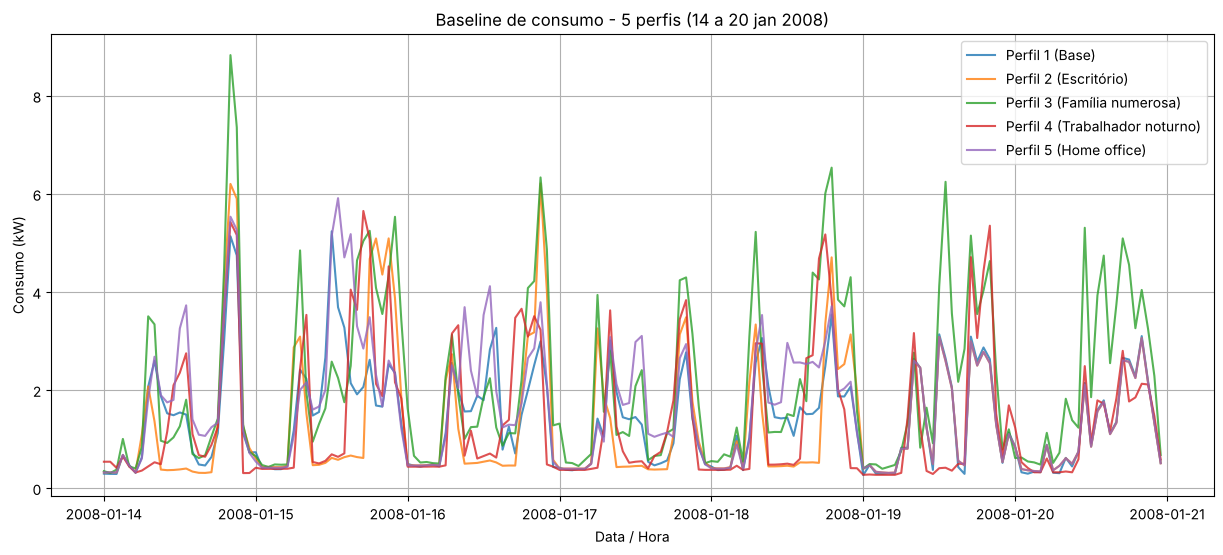

In [12]:
# 6.3 Hora de início dos ciclos em cada perfil
nomes = {
    'Perfil_1_Original': 'Perfil 1 (Base)',
    'Perfil_2_Escritorio': 'Perfil 2 (Escritório)',
    'Perfil_3_Familia': 'Perfil 3 (Família numerosa)',
    'Perfil_4_Noturno': 'Perfil 4 (Trabalhador noturno)',
    'Perfil_5_HomeOffice': 'Perfil 5 (Home office)',
}
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5), sharey=True)
for ax, p in zip(axes, perfis):
    ev = eventos[eventos['perfil'] == p]
    uteis = ev['inicio'].dt.dayofweek < 5
    for m in ['maq_lavar', 'maq_secar', 'maq_loica']:
        h = ev.loc[uteis & (ev['maquina'] == m), 'inicio'].dt.hour
        ax.plot(np.bincount(h, minlength=24) / max(len(h), 1), label=m, color=cores[m])
    ax.set_title(nomes[p], fontsize=10); ax.set_xticks(range(0, 24, 4)); ax.set_xlabel('Hora (dias úteis)')
axes[0].set_ylabel('Fração dos ciclos'); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

# 6.4 Perfil médio horário: carga não deslocável vs baseline total (dias úteis)
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5), sharey=True)
uteis_d = ~fim_de_semana
for ax, p in zip(axes, perfis):
    ax.fill_between(horas, perfis[p][uteis_d].mean(axis=0), baseline[p][uteis_d].mean(axis=0),
                    alpha=.4, label='máquinas')
    ax.plot(horas, perfis[p][uteis_d].mean(axis=0), label='não deslocável')
    ax.plot(horas, baseline[p][uteis_d].mean(axis=0), 'k', lw=1, label='baseline total')
    ax.set_title(nomes[p], fontsize=10); ax.set_xticks(range(0, 24, 4)); ax.set_xlabel('Hora (dias úteis)')
axes[0].set_ylabel('kW médios'); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

# 6.5 Uma semana típica (segunda a domingo) para ver a diferença entre perfis
semana = (dias >= '2008-01-14') & (dias <= '2008-01-20')
t = pd.date_range('2008-01-14', periods=semana.sum() * 24, freq='h')
plt.figure(figsize=(15, 6))
for p in perfis:
    plt.plot(t, baseline[p][semana].ravel(), label=nomes[p], alpha=0.8)
plt.title('Baseline de consumo - 5 perfis (14 a 20 jan 2008)')
plt.ylabel('Consumo (kW)'); plt.xlabel('Data / Hora'); plt.legend(); plt.grid(True); plt.show()

## 7. Exportar

| Ficheiro | Conteúdo |
|---|---|
| `carga_base.csv` | Datetime × 5 perfis — carga **não deslocável** (kW médio na hora = kWh) |
| `baseline_total.csv` | Datetime × 5 perfis — carga não deslocável + máquinas (substitui o `dataset_consumo_simulado.csv`) |
| `eventos.csv` | um ciclo por linha: perfil, máquina, `ciclo_id`, origem (`real` / `realocado` / `extra`), início, fim, duração, energia, potência média |
| `ciclos_curvas.csv` | curva de potência real de cada ciclo (`ciclo_id`, minuto desde o início, kW) — o otimizador usa-a ao deslocar um evento |
| `disponibilidade.csv` | Datetime × 5 perfis — 1 se a pessoa está em casa e acordada nessa hora (janela onde pode ligar uma máquina) |

In [13]:
def para_csv(dicionario, ficheiro, casas=3):
    tabela = pd.DataFrame({p: pd.DataFrame(np.asarray(m), index=dias, columns=horas).stack().to_numpy()
                           for p, m in dicionario.items()})
    idx = pd.DataFrame(np.zeros((D, 24)), index=dias, columns=horas).stack().index
    tabela.index = pd.DatetimeIndex(idx.get_level_values(0) + pd.to_timedelta(idx.get_level_values(1), unit='h'),
                                    name='Datetime')
    tabela.round(casas).to_csv(ficheiro)
    return tabela


para_csv(perfis, 'carga_base.csv')
para_csv(baseline, 'baseline_total.csv')
para_csv({p: d.astype(int) for p, d in disponivel.items()}, 'disponibilidade.csv', casas=0)
eventos.to_csv('eventos.csv', index=False)
pd.DataFrame([(c, m, round(kw, 4)) for c, curva in curvas.items() if c in set(eventos['ciclo_id'])
              for m, kw in enumerate(curva)],
             columns=['ciclo_id', 'minuto', 'kw']).to_csv('ciclos_curvas.csv', index=False)

print(f"Exportado: {D * 24:,} horas x {len(perfis)} perfis | {len(eventos):,} eventos | "
      f"{eventos['ciclo_id'].nunique():,} curvas de ciclos reais")

Exportado: 34,056 horas x 5 perfis | 13,842 eventos | 2,563 curvas de ciclos reais
